In [1]:
import ee

In [2]:
import geemap

In [3]:
import folium

In [4]:
import numpy as np

In [5]:
import pandas as pd

In [6]:
import matplotlib.pyplot as plt

In [7]:
import seaborn as sns

In [8]:
from IPython.display import display

In [9]:
ee.Authenticate()

True

In [10]:
ee.Initialize()

In [11]:
asset_path = 'projects/booming-skill-496914-d5/assets/Palamu_AOI'
Palamu_AOI = ee.FeatureCollection(asset_path)
print("Palamu AOI loaded")

Palamu AOI loaded


In [12]:
def add_ee_layer(self, ee_image_object, vis_params, name):
    map_id_dict = ee.Image(ee_image_object).getMapId(vis_params)
    folium.raster_layers.TileLayer(
        tiles=map_id_dict['tile_fetcher'].url_format,
        attr='Map Data © Google Earth Engine',
        name=name,
        overlay=True,
        control=True
    ).add_to(self)

In [13]:
folium.Map.add_ee_layer = add_ee_layer

In [14]:
print("Processing Thematic Layers (DEM & Slope)")
dem = ee.Image('USGS/SRTMGL1_003').clip(Palamu_AOI)
slope = ee.Terrain.slope(dem).clip(Palamu_AOI)

Processing Thematic Layers (DEM & Slope)


In [15]:
print("Thematic Layers (DEM aur Slope)")
dem = ee.Image('USGS/SRTMGL1_003').clip(Palamu_AOI)
slope = ee.Terrain.slope(dem).clip(Palamu_AOI)
print("MAP 1: Thematic Layer (Slope Map)")
map1 = folium.Map(location=[24.0, 84.1], zoom_start=9)
slope_vis = {'min': 0, 'max': 30, 'palette': ['green', 'yellow', 'orange', 'red']} 
map1.add_ee_layer(slope, slope_vis, 'Slope Map')
empty = ee.Image().byte()
outline = empty.paint(featureCollection=ee.FeatureCollection(Palamu_AOI), color=1, width=3)
map1.add_ee_layer(outline, {'palette': ['000000']}, 'Palamu Boundary')
map1.add_child(folium.LayerControl())
display(map1)

Thematic Layers (DEM aur Slope)
MAP 1: Thematic Layer (Slope Map)


In [16]:
def mask_clouds(image):
    qa = image.select('QA_PIXEL')
    cloud_shadow_bit_mask = 1 << 4
    clouds_bit_mask = 1 << 3
    mask = qa.bitwiseAnd(cloud_shadow_bit_mask).eq(0).And(qa.bitwiseAnd(clouds_bit_mask).eq(0))
    return image.updateMask(mask)

In [17]:
landsat = ee.ImageCollection("LANDSAT/LC08/C02/T1_TOA") \
    .filterBounds(Palamu_AOI) \
    .filterDate('2023-01-01', '2023-12-31') \
    .filterMetadata('CLOUD_COVER', 'less_than', 5) \
    .map(mask_clouds).median().clip(Palamu_AOI)

In [18]:
ndvi = landsat.normalizedDifference(['B5', 'B4'])
ndwi = landsat.normalizedDifference(['B3', 'B5'])

In [19]:
lulc = ee.Image(1) \
    .where(ndvi.gt(0.2), 2) \
    .where(ndwi.gt(0.1), 3) \
    .clip(Palamu_AOI)

In [20]:
print("MAP 2: Land Cover (LULC) Map")
map2 = folium.Map(location=[24.0, 84.1], zoom_start=9)
lulc_vis = {'min': 1, 'max': 3, 'palette': ['red', 'green', 'blue']} 
map2.add_ee_layer(lulc, lulc_vis, 'LULC Classified')
empty = ee.Image().byte()
outline = empty.paint(featureCollection=ee.FeatureCollection(Palamu_AOI), color=1, width=3)
map2.add_ee_layer(outline, {'palette': ['000000']}, 'Palamu Boundary')
map2.add_child(folium.LayerControl())
display(map2)

MAP 2: Land Cover (LULC) Map


In [21]:
slope_reclass = ee.Image(1) \
    .where(slope.lt(5), 4) \
    .where(slope.gte(5).And(slope.lt(15)), 3) \
    .where(slope.gte(15).And(slope.lt(30)), 2) \
    .clip(Palamu_AOI)

In [22]:
lulc_reclass = ee.Image(1) \
    .where(lulc.eq(3), 4) \
    .where(lulc.eq(2), 3) \
    .where(lulc.eq(1), 1) \
    .clip(Palamu_AOI)

In [23]:
gw_index = (slope_reclass.multiply(0.6)).add(lulc_reclass.multiply(0.4))

In [24]:
gw_zones = ee.Image(1) \
    .where(gw_index.gt(2.0).And(gw_index.lte(2.5)), 2) \
    .where(gw_index.gt(2.5).And(gw_index.lte(3.2)), 3) \
    .where(gw_index.gt(3.2), 4) \
    .clip(Palamu_AOI)

In [25]:
print("MAP 3: Groundwater Potential Zonation Map")
map3 = folium.Map(location=[24.0, 84.1], zoom_start=9)
gw_vis = {'min': 1, 'max': 4, 'palette': ['red', 'orange', 'lightgreen', 'blue']}
map3.add_ee_layer(gw_zones, gw_vis, 'GW Potential Zones')
empty = ee.Image().byte()
outline = empty.paint(featureCollection=ee.FeatureCollection(Palamu_AOI), color=1, width=3)
map3.add_ee_layer(outline, {'palette': ['000000']}, 'Palamu Boundary')
map3.add_child(folium.LayerControl())
display(map3)

MAP 3: Groundwater Potential Zonation Map


In [26]:
print("MAP 4: Final Cartographic Groundwater Map (with Palamu Boundary)")
map4 = folium.Map(location=[24.0, 84.1], zoom_start=9)
gw_vis = {'min': 1, 'max': 4, 'palette': ['red', 'orange', 'lightgreen', 'blue']}
map4.add_ee_layer(gw_zones, gw_vis, 'GW Potential')
outline = ee.Image().byte().paint(featureCollection=ee.FeatureCollection(Palamu_AOI), color=1, width=3)
map4.add_ee_layer(outline, {'palette': ['000000']}, 'Palamu Boundary')
map4.add_child(folium.LayerControl())
display(map4)

MAP 4: Final Cartographic Groundwater Map (with Palamu Boundary)


In [27]:
pixel_area = ee.Image.pixelArea().divide(1e6) 
zone_areas = pixel_area.addBands(gw_zones).reduceRegion(
    reducer=ee.Reducer.sum().group(
        groupField=1,
        groupName='zone'
    ),
    geometry=Palamu_AOI,
    scale=30,
    maxPixels=1e10
).get('groups')

In [28]:
area_data = zone_areas.getInfo()
data_list = []
class_names = {1: 'Low Potential', 2: 'Moderate Potential', 3: 'High Potential', 4: 'Very High Potential'}

In [29]:
for item in area_data:
    zone_class = item['zone']
    area_sqkm = round(item['sum'], 2)
    data_list.append([class_names.get(zone_class, 'Unknown'), area_sqkm])
    
df_areas = pd.DataFrame(data_list, columns=['Groundwater Zone', 'Area (Sq Km)'])
print("\n--- Palamu Groundwater Zones Area Statistics ---")
display(df_areas)


--- Palamu Groundwater Zones Area Statistics ---


,Groundwater Zone,Area (Sq Km)
0,Low Potential,17.31
1,Moderate Potential,136.90
2,High Potential,878.13
3,Very High Potential,3384.99


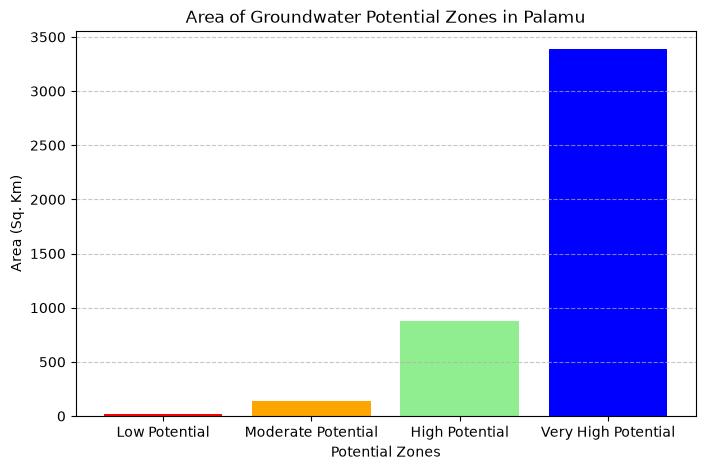

In [30]:
plt.figure(figsize=(8, 5))
plt.bar(df_areas['Groundwater Zone'], df_areas['Area (Sq Km)'], color=['red', 'orange', 'lightgreen', 'blue'])
plt.title('Area of Groundwater Potential Zones in Palamu')
plt.xlabel('Potential Zones')
plt.ylabel('Area (Sq. Km)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()